# Black Friday Sales Analysis — NumPy, Pandas & Visualization

**Practice notebook for data analysis using `retail_black_friday_sales_100k.csv`**
[Dataset Link](https://drive.google.com/file/d/1Y4XBKfdo6rhLX2B7F9EGOgMepJ7E1Vsq/view?usp=sharing)

## Learning outcomes
By the end of this notebook, you should be able to:
- inspect and validate a real-world-style transaction dataset;
- use NumPy for numerical summaries and vectorized calculations;
- use Pandas to filter, group, aggregate, and transform transaction data;
- communicate findings with Matplotlib, Seaborn, and Plotly;
- interpret basic statistical comparisons without confusing correlation with causation.

**Dataset grain:** each row represents a transaction. The dataset has 100,000 rows and fields about customers, products, prices, discounts, purchase time, and Black Friday status. Treat the file as a practice dataset; verify its contents before making business claims.


## 1. Setup and load the dataset from Google Drive

This notebook is configured to read the CSV from **Google Drive**, rather than asking you to upload it from your computer.

**Before running the notebook:**
1. Put `retail_black_friday_sales_100k.csv` in your Google Drive, preferably in **My Drive**.
2. Run the next cell and authorize Colab to access Drive.
3. If your CSV is inside a folder, update `FILE_PATH` to that folder's path.

**Concept:** mounting Drive makes your Drive files available to the Colab runtime. The path must match the file's actual location.


In [3]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



# Update this path if the CSV is stored inside a folder in My Drive.
FILE_PATH = "retail_black_friday_sales_100k.csv"

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(
        f"Could not find the CSV at: {FILE_PATH}\n"
        "Check the file name and update FILE_PATH to its exact Google Drive location."
    )

df = pd.read_csv(FILE_PATH)
print("Loaded file:", FILE_PATH)
print("Shape:", df.shape)
display(df.head())


Loaded file: retail_black_friday_sales_100k.csv
Shape: (100000, 18)


,transaction_id,customer_id,age_group,gender,city,customer_segment,product_id,product_category,original_price,discount_pct,final_price,quantity,purchase_amount,payment_method,purchase_date,purchase_hour,is_weekend,is_black_friday
0,T0000001,C007297,26-35,Male,San Francisco,Loyal,P2713,Footwear,153.73,35,99.92,1,99.92,Credit Card,2025-12-01,0,0,0
1,T0000002,C001640,56+,Other,Dallas,Returning,P7219,Beauty,230.05,40,138.03,1,138.03,PayPal,2025-11-24,5,0,0
2,T0000003,C018025,26-35,Male,Phoenix,New,P5521,Groceries,174.67,25,131.00,1,131.00,Credit Card,2025-11-24,14,0,0
3,T0000004,C016050,18-25,Other,Miami,VIP,P3003,Sports,399.61,40,239.77,1,239.77,Credit Card,2025-11-30,23,1,0
4,T0000005,C014629,46-55,Male,Los Angeles,Loyal,P4633,Footwear,120.87,30,84.61,2,169.22,Debit Card,2025-11-25,2,0,0


In [7]:
%pip install pandas

  Using cached pandas-3.0.6-cp311-cp311-macosx_11_0_arm64.whl (10.0 MB)

[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [9]:
%pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)

[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Understand the columns

| Column | Meaning |
|---|---|
| `transaction_id` | Unique transaction identifier |
| `customer_id` | Customer identifier |
| `age_group`, `gender`, `city` | Customer descriptors |
| `customer_segment` | Segment such as New, Returning, Loyal, or VIP |
| `product_id`, `product_category` | Product information |
| `original_price` | Price before discount |
| `discount_pct` | Discount percentage |
| `final_price` | Price after discount, per item |
| `quantity` | Number of units in the transaction |
| `purchase_amount` | Total amount paid for the transaction |
| `payment_method` | Payment type |
| `purchase_date`, `purchase_hour` | Purchase date and hour |
| `is_weekend` | Weekend indicator (0/1) |
| `is_black_friday` | Black Friday indicator (0/1) |

**Business framing:** a retailer may use these data to understand sales mix, customer segments, discount patterns, peak shopping times, and differences between Black Friday and other dates.

**Important:** `purchase_amount` is transaction value, not necessarily profit. Profit analysis would require cost of goods sold, fulfillment costs, and other expense fields.

In [12]:
# Inspect types, missing values, and duplicate rows
print(df.info())
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_values"))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate transaction IDs:", df["transaction_id"].duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   transaction_id    100000 non-null  str    
 1   customer_id       100000 non-null  str    
 2   age_group         100000 non-null  str    
 3   gender            100000 non-null  str    
 4   city              100000 non-null  str    
 5   customer_segment  100000 non-null  str    
 6   product_id        100000 non-null  str    
 7   product_category  100000 non-null  str    
 8   original_price    100000 non-null  float64
 9   discount_pct      100000 non-null  int64  
 10  final_price       100000 non-null  float64
 11  quantity          100000 non-null  int64  
 12  purchase_amount   100000 non-null  float64
 13  payment_method    100000 non-null  str    
 14  purchase_date     100000 non-null  str    
 15  purchase_hour     100000 non-null  int64  
 16  is_weekend        100000 non-nul

,missing_values
transaction_id,0
customer_id,0
is_weekend,0
purchase_hour,0
purchase_date,0
payment_method,0
purchase_amount,0
quantity,0
final_price,0
discount_pct,0


Duplicate rows: 0
Duplicate transaction IDs: 0


## 3. Concept: NumPy arrays and vectorization

NumPy provides efficient numerical arrays and vectorized operations. Instead of looping over every transaction in Python, apply arithmetic to an entire column or array.

- **Array:** a collection of values of a compatible type.
- **Shape:** the dimensions of an array.
- **Vectorization:** applying an operation to many values at once.
- **Broadcasting:** NumPy's rules for combining arrays of compatible shapes.

In this dataset, NumPy can help summarize transaction amounts, inspect distributions, and calculate derived numerical measures.

## Solved Example 1 — NumPy summary of transaction amounts

**Question:** What are the mean, median, minimum, maximum, and standard deviation of transaction values?

**Interpretation tip:** the mean is sensitive to unusually large transactions, while the median is more resistant to outliers. A gap between them can indicate a right-skewed distribution.

In [13]:
amounts = df["purchase_amount"].to_numpy()

print("Array shape:", amounts.shape)
print(f"Mean transaction value:   {np.mean(amounts):,.2f}")
print(f"Median transaction value: {np.median(amounts):,.2f}")
print(f"Minimum transaction value:{np.min(amounts):,.2f}")
print(f"Maximum transaction value:{np.max(amounts):,.2f}")
print(f"Std. deviation:           {np.std(amounts, ddof=1):,.2f}")

Array shape: (100000,)
Mean transaction value:   351.26
Median transaction value: 161.15
Minimum transaction value:2.22
Maximum transaction value:11,441.80
Std. deviation:           589.86


## 4. Concept: Pandas selection and filtering

Pandas `DataFrame` objects represent tabular data. Use:
- `df["column"]` to select one column;
- `df.loc[condition, columns]` to filter rows and select columns;
- `sort_values()` to rank records;
- `value_counts()` to count category frequency.

Filtering is useful for targeted business questions, such as examining VIP transactions or transactions with high discounts. Always check how many records remain after a filter.

## Solved Example 2 — Find high-value transactions

**Question:** Show the 10 transactions with the largest purchase amounts.

This is useful for checking high-ticket purchases, but it does not by itself explain why those transactions are large.

In [6]:
top_transactions = (
    df.loc[:, ["transaction_id", "customer_segment", "product_category",
               "quantity", "discount_pct", "purchase_amount"]]
      .sort_values("purchase_amount", ascending=False)
      .head(10)
)
display(top_transactions)

,transaction_id,customer_segment,product_category,quantity,discount_pct,purchase_amount
6387,T0006388,Returning,Electronics,5,5,11441.80
34866,T0034867,VIP,Electronics,5,10,11071.05
6647,T0006648,Returning,Electronics,5,5,11066.55
17553,T0017554,Returning,Electronics,5,15,10591.35
51066,T0051067,Loyal,Electronics,5,15,10265.70
3041,T0003042,New,Electronics,5,5,10240.40
74498,T0074499,Returning,Electronics,5,20,9575.20
22434,T0022435,New,Electronics,5,20,9537.30
27967,T0027968,Returning,Electronics,5,15,9252.70
41908,T0041909,Returning,Electronics,5,20,9200.60


## 5. Concept: Grouping and aggregation

`groupby()` splits data into groups, applies calculations, and combines the results. Common aggregations include:
- `sum`: total sales value;
- `mean`: average transaction or unit value;
- `count` / `nunique`: transaction or customer counts;
- `median`: typical value less affected by extreme observations.

Choose the metric that matches the business question. **Total sales** and **average transaction value** answer different questions. A category can have high total sales because it has many transactions, even if its average transaction is modest.

## Solved Example 3 — Sales by product category

**Question:** Which product categories contribute the most transaction value?

The result includes transaction count, total sales, average transaction value, and units sold. Sort by total sales to identify categories contributing the most observed revenue.

In [7]:
category_summary = (
    df.groupby("product_category", as_index=False)
      .agg(
          transactions=("transaction_id", "nunique"),
          total_sales=("purchase_amount", "sum"),
          avg_transaction_value=("purchase_amount", "mean"),
          units_sold=("quantity", "sum")
      )
      .sort_values("total_sales", ascending=False)
)

display(category_summary.round(2))

,product_category,transactions,total_sales,avg_transaction_value,units_sold
4,Electronics,9974,14123441.47,1416.03,14502
7,Home & Kitchen,9886,6461099.92,653.56,14393
8,Sports,9975,3303563.29,331.18,14503
0,Accessories,10156,2754561.54,271.23,14732
5,Footwear,10104,2013317.39,199.26,14529
3,Clothing,9911,1688471.88,170.36,14317
9,Toys,10054,1669209.91,166.02,14663
1,Beauty,9984,1374751.97,137.70,14385
6,Groceries,9925,1075986.12,108.41,14268
2,Books,10031,661227.18,65.92,14437


## 6. Concept: Dates, time features, and business metrics

Dates should be converted to a datetime type before time-based analysis. Once parsed, Pandas can derive day, month, weekday, or hour-level summaries.

A useful metric is **average transaction value (ATV)**:

\[
ATV = \frac{\text{Total transaction value}}{\text{Number of transactions}}
\]

This dataset spans a limited sales period, so describe the period represented in the file before making seasonal claims. A single period is not enough to establish a recurring yearly pattern.

## Solved Example 4 — Compare Black Friday and non-Black-Friday transactions

**Question:** How do transaction count, total sales, average transaction value, and average discount differ by Black Friday status?

The code labels the binary indicator for readability. The result is descriptive, not proof that Black Friday caused any difference; other factors may also vary.

In [5]:
df["purchase_date"] = pd.to_datetime(df["purchase_date"], errors="coerce")

black_friday_summary = (
    df.assign(
        shopping_period=np.where(df["is_black_friday"].eq(1),
                                 "Black Friday", "Other dates")
    )
    .groupby("shopping_period", as_index=False)
    .agg(
        transactions=("transaction_id", "nunique"),
        total_sales=("purchase_amount", "sum"),
        avg_transaction_value=("purchase_amount", "mean"),
        avg_discount_pct=("discount_pct", "mean"),
        units_sold=("quantity", "sum")
    )
)

display(black_friday_summary.round(2))

,shopping_period,transactions,total_sales,avg_transaction_value,avg_discount_pct,units_sold
0,Black Friday,12633,4382528.94,346.91,26.64,18282
1,Other dates,87367,30743101.73,351.88,26.63,126447


## 7. Visualization concepts

### Matplotlib
Matplotlib is a flexible plotting foundation. It is useful when you need detailed control over figure size, axes, labels, annotations, and export.

### Seaborn
Seaborn builds on Matplotlib and makes statistical plots easier to create. It is especially useful for comparing distributions and relationships across categories.

### Plotly
Plotly creates interactive charts that support hover details, zooming, and legend interaction. It is useful for exploratory analysis and shareable HTML reports.

**Chart selection guide**
- Bar chart: compare totals or averages across categories.
- Histogram: inspect the distribution of a numerical variable.
- Box plot: compare spread and potential outliers across groups.
- Scatter plot: explore relationships between two numerical variables.
- Line chart: show a metric changing over time.

A chart should answer a question. Include a clear title, readable labels, appropriate units, and a brief interpretation.

## Sample snippet — Matplotlib: sales by category

Use this after reviewing the grouped table. The chart ranks categories by total transaction value.

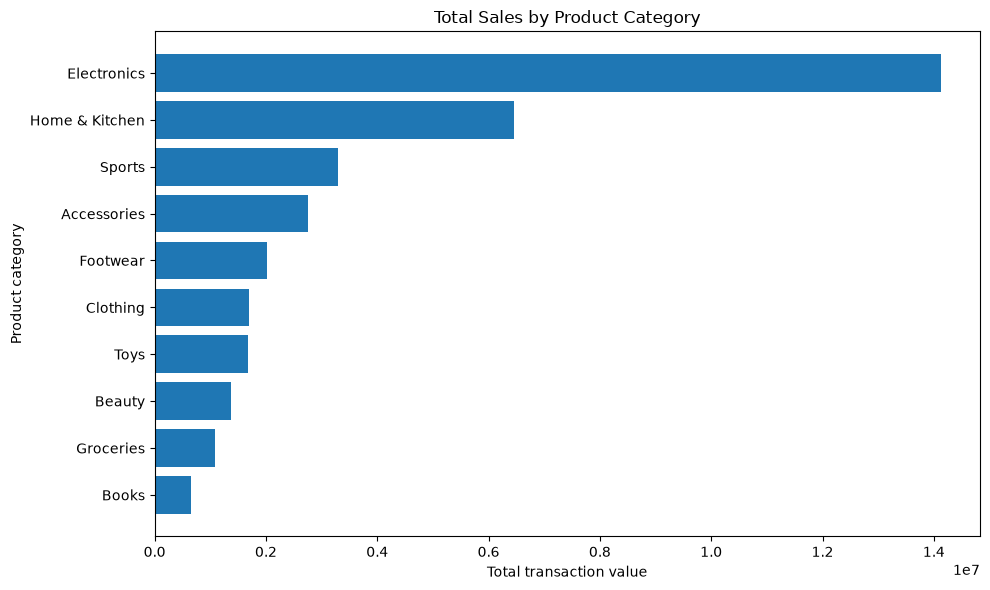

In [8]:
plot_data = category_summary.sort_values("total_sales", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_data["product_category"], plot_data["total_sales"])
plt.xlabel("Total transaction value")
plt.ylabel("Product category")
plt.title("Total Sales by Product Category")
plt.tight_layout()
plt.show()

## Sample snippet — Seaborn: transaction-value distribution

A histogram helps show whether transaction values are concentrated in a narrow range or have a long tail. The optional log scale can help when values vary substantially, but explain the scale when presenting the chart.

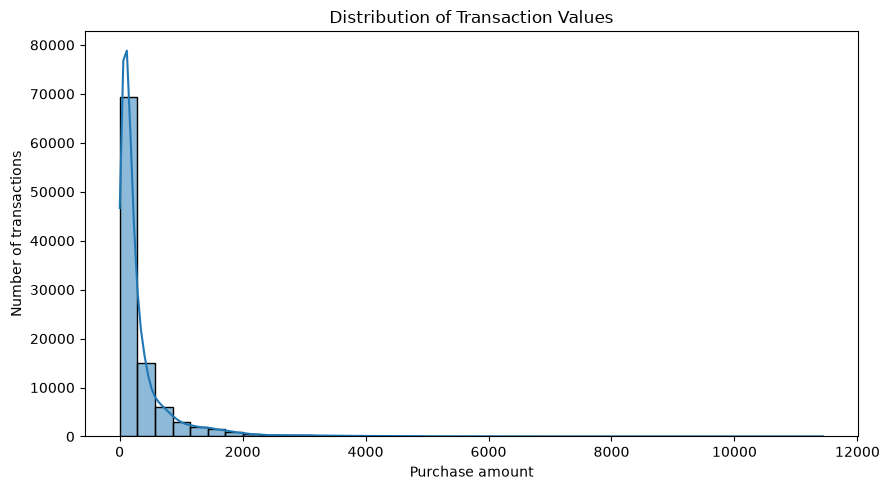

In [9]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="purchase_amount", bins=40, kde=True)
plt.title("Distribution of Transaction Values")
plt.xlabel("Purchase amount")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()

## Sample snippet — Plotly: interactive category comparison

Plotly is optional in this notebook. Install it in Colab if needed. The hover tooltip makes it easier to inspect values without crowding the chart with labels.

In [10]:

import plotly.express as px

fig = px.bar(
    category_summary.sort_values("total_sales", ascending=False),
    x="product_category",
    y="total_sales",
    hover_data=["transactions", "avg_transaction_value", "units_sold"],
    title="Interactive Sales by Product Category",
    labels={"product_category": "Product category",
            "total_sales": "Total transaction value"}
)
fig.show()

In [24]:
%pip install --upgrade nbformat ipython


[notice] A new release of pip is available: 23.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 8. Statistical thinking: association, uncertainty, and limitations

Descriptive statistics summarize what is in the dataset. Inferential statistics attempt to quantify uncertainty or assess whether an observed pattern is compatible with a statistical model.

Keep these principles in mind:
1. **Association is not causation.** A relationship between discounts and purchase amounts does not prove discounts caused the amount.
2. **Check group sizes.** An average based on a small group can be unstable.
3. **Inspect distributions.** Means can be misleading with skewed data or outliers.
4. **Avoid leakage.** Do not use information unavailable at prediction time if building a model.
5. **Validate assumptions.** Statistical tests rely on assumptions about sampling, independence, and distributions.
6. **Distinguish sales from profit.** This dataset does not contain product costs, so it cannot establish profitability.

For a more advanced extension, `statsmodels` can estimate regression models and provide confidence intervals. A regression coefficient is an association conditional on the model—not automatically a causal effect.

# Practice Set

Complete the following **6 unsolved questions**. For each task, add a short business interpretation after the code. Do not just print a table or chart—explain what the result means and mention one limitation.

## Unsolved Question 1 — Customer segment performance

Calculate, for each `customer_segment`:
- number of unique customers;
- number of transactions;
- total purchase amount;
- average transaction value.

Sort the result by total purchase amount. Which segment contributes the most total sales, and does it also have the highest average transaction value?

In [11]:
# TODO: Group by customer_segment and calculate the four requested metrics.
# Hint: groupby(...).agg(...)
segment_summary = df.groupby("customer_segment").agg(
    unique_customers=("customer_id", "nunique"),
    transactions=("transaction_id", "nunique"),
    total_purchase_amount=("purchase_amount", "sum"),
    avg_transaction_value=("purchase_amount", "mean")
).reset_index()


segment_summary = segment_summary.sort_values(
    by="total_purchase_amount",
    ascending=False
)

display(segment_summary)

,customer_segment,unique_customers,transactions,total_purchase_amount,avg_transaction_value
2,Returning,22141,34946,12125507.74,346.978416
1,New,20192,29956,10574443.42,352.999179
0,Loyal,17969,25130,8888416.70,353.697441
3,VIP,8658,9968,3537262.81,354.861839


## Unsolved Question 2 — Discount analysis by product category

For each `product_category`, calculate:
- average discount percentage;
- average quantity per transaction;
- average purchase amount.

Sort by average discount. Identify a category with a high average discount and discuss whether its average purchase amount is also high. Do not claim causation from this comparison.

In [13]:
# TODO: Group by product_category and calculate the requested metrics.
# Group by product category
segment_summary = df.groupby("customer_segment").agg(
    unique_customers=("customer_id", "nunique"),
    transactions=("transaction_id", "nunique"),
    total_purchase_amount=("purchase_amount", "sum"),
    avg_transaction_value=("purchase_amount", "mean")
).reset_index()

# Sort by total purchase amount (highest first)
segment_summary = segment_summary.sort_values(
    by="total_purchase_amount",
    ascending=False
)

display(segment_summary)

,customer_segment,unique_customers,transactions,total_purchase_amount,avg_transaction_value
2,Returning,22141,34946,12125507.74,346.978416
1,New,20192,29956,10574443.42,352.999179
0,Loyal,17969,25130,8888416.70,353.697441
3,VIP,8658,9968,3537262.81,354.861839


## Unsolved Question 3 — Purchase-hour pattern

Create a summary by `purchase_hour` with transaction count and total purchase amount. Plot both metrics in separate charts or use a suitable combined visualization.

Which hours have the most transactions? Are those also the hours with the highest sales value?

Purchase-hour Summary:


,purchase_hour,transaction_count,total_purchase_amount
0,0,4121,1426468.73
1,1,4103,1459034.87
2,2,4218,1489355.50
3,3,4191,1446826.91
4,4,4193,1420621.20
5,5,4234,1532048.19
6,6,4238,1469634.64
7,7,4228,1460131.67
8,8,4054,1481453.65
9,9,4160,1436557.44


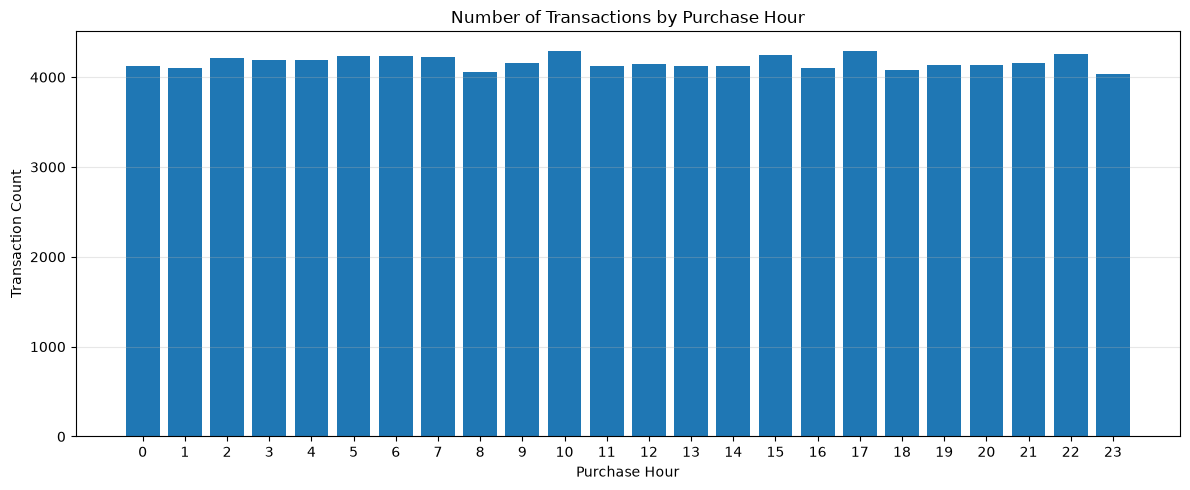

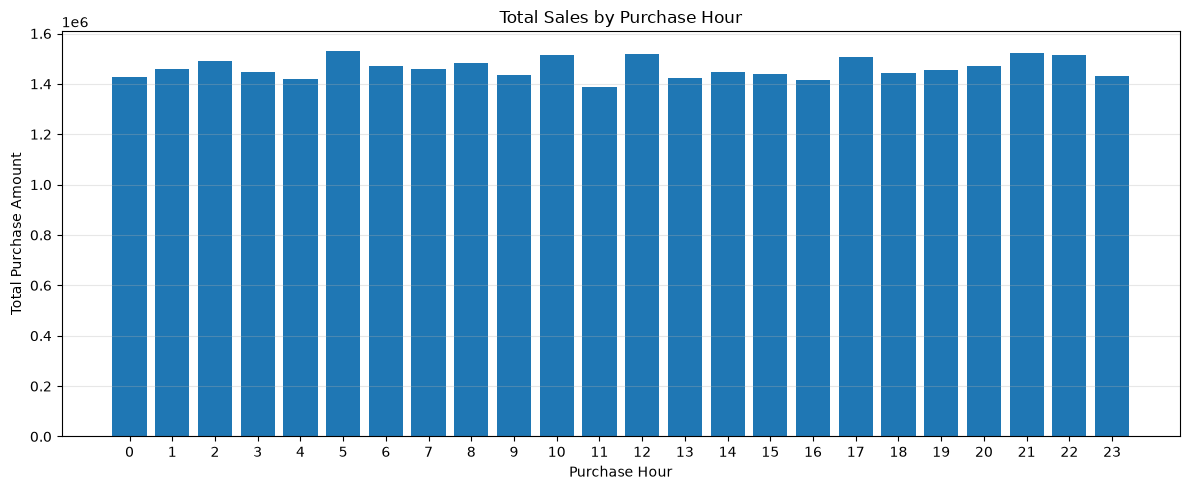


Analysis:
Hour with the most transactions: 10.0
Number of transactions: 4295.0

Hour with the highest sales: 5.0
Total sales: 1532048.19

Conclusion: No, the hour with the most transactions does not have the highest sales.


In [14]:
# TODO: Group by purchase_hour, aggregate, sort, and visualize.

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Group by purchase_hour and calculate metrics
hour_summary = df.groupby("purchase_hour").agg(
    transaction_count=("transaction_id", "nunique"),
    total_purchase_amount=("purchase_amount", "sum")
).reset_index()

# Step 2: Sort by purchase hour
hour_summary = hour_summary.sort_values(
    by="purchase_hour"
)

# Display summary
print("Purchase-hour Summary:")
display(hour_summary)

# Step 3: Plot transaction count by hour
plt.figure(figsize=(12, 5))
plt.bar(
    hour_summary["purchase_hour"],
    hour_summary["transaction_count"]
)
plt.title("Number of Transactions by Purchase Hour")
plt.xlabel("Purchase Hour")
plt.ylabel("Transaction Count")
plt.xticks(hour_summary["purchase_hour"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 4: Plot total purchase amount by hour
plt.figure(figsize=(12, 5))
plt.bar(
    hour_summary["purchase_hour"],
    hour_summary["total_purchase_amount"]
)
plt.title("Total Sales by Purchase Hour")
plt.xlabel("Purchase Hour")
plt.ylabel("Total Purchase Amount")
plt.xticks(hour_summary["purchase_hour"])
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 5: Identify the hour with the most transactions
busiest_hour = hour_summary.loc[
    hour_summary["transaction_count"].idxmax()
]

# Step 6: Identify the hour with the highest sales
highest_sales_hour = hour_summary.loc[
    hour_summary["total_purchase_amount"].idxmax()
]

print("\nAnalysis:")
print(
    f"Hour with the most transactions: "
    f"{busiest_hour['purchase_hour']}"
)
print(
    f"Number of transactions: "
    f"{busiest_hour['transaction_count']}"
)

print(
    f"\nHour with the highest sales: "
    f"{highest_sales_hour['purchase_hour']}"
)
print(
    f"Total sales: "
    f"{highest_sales_hour['total_purchase_amount']:.2f}"
)

# Step 7: Compare both hours
if busiest_hour["purchase_hour"] == highest_sales_hour["purchase_hour"]:
    print(
        "\nConclusion: Yes, the hour with the most transactions "
        "also has the highest sales."
    )
else:
    print(
        "\nConclusion: No, the hour with the most transactions "
        "does not have the highest sales."
    )


## Unsolved Question 4 — Payment-method preferences

Calculate transaction count, total purchase amount, and average transaction value for each `payment_method`. Also calculate each payment method's percentage of all transactions.

Which payment method is most frequently used? Is the most frequent method also the one with the highest average transaction value?

Payment Method Summary:


,payment_method,transaction_count,total_purchase_amount,avg_transaction_value,transaction_share_pct
2,Debit Card,16772,5892551.34,351.33,16.77
4,Mobile Wallet,16711,6020177.60,360.25,16.71
0,Cash,16680,5856797.42,351.13,16.68
1,Credit Card,16663,5877297.96,352.72,16.66
3,Gift Card,16614,5708216.94,343.58,16.61
5,PayPal,16560,5770589.41,348.47,16.56


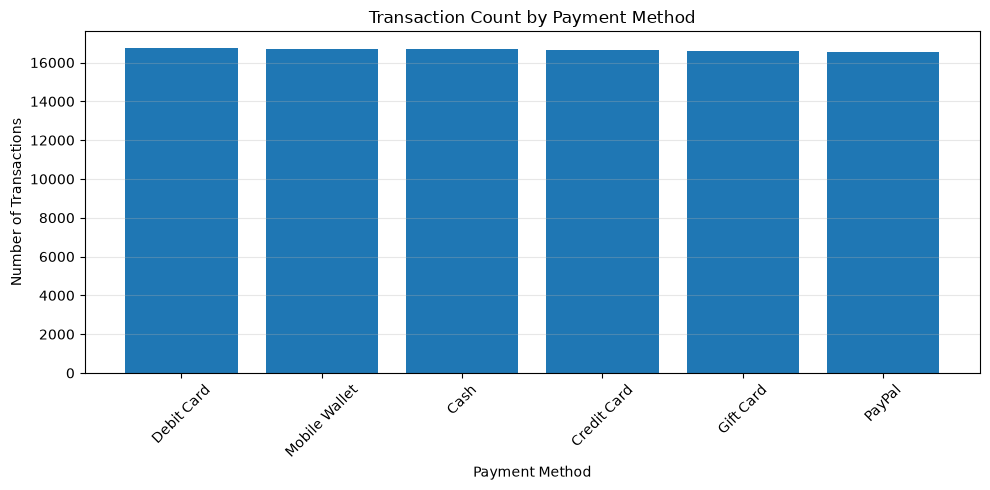


Analysis:
Most frequently used payment method: Debit Card
Number of transactions: 16772
Transaction share: 16.77 %

Payment method with the highest average transaction value: Mobile Wallet
Average transaction value: 360.25

Conclusion: No, the most frequently used method does not have the highest average transaction value.


In [15]:
# TODO: Group by payment_method.
# Hint: transaction share (%) = transactions / total transactions * 100

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Group by payment_method and calculate metrics
payment_summary = df.groupby("payment_method").agg(
    transaction_count=("transaction_id", "nunique"),
    total_purchase_amount=("purchase_amount", "sum"),
    avg_transaction_value=("purchase_amount", "mean")
).reset_index()

# Step 2: Calculate each payment method's percentage of all transactions
total_transactions = payment_summary["transaction_count"].sum()

payment_summary["transaction_share_pct"] = (
    payment_summary["transaction_count"] / total_transactions * 100
)

# Step 3: Sort by transaction count (highest first)
payment_summary = payment_summary.sort_values(
    by="transaction_count",
    ascending=False
)

# Display summary
print("Payment Method Summary:")
display(payment_summary.round(2))

# Step 4: Plot transaction count by payment method
plt.figure(figsize=(10, 5))
plt.bar(
    payment_summary["payment_method"],
    payment_summary["transaction_count"]
)
plt.title("Transaction Count by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 5: Find the most frequently used payment method
most_frequent = payment_summary.loc[
    payment_summary["transaction_count"].idxmax()
]

# Step 6: Find the payment method with the highest average transaction value
highest_avg = payment_summary.loc[
    payment_summary["avg_transaction_value"].idxmax()
]

print("\nAnalysis:")
print("Most frequently used payment method:",
      most_frequent["payment_method"])
print("Number of transactions:",
      most_frequent["transaction_count"])
print("Transaction share:",
      round(most_frequent["transaction_share_pct"], 2), "%")

print("\nPayment method with the highest average transaction value:",
      highest_avg["payment_method"])
print("Average transaction value:",
      round(highest_avg["avg_transaction_value"], 2))

# Step 7: Compare the two payment methods
if most_frequent["payment_method"] == highest_avg["payment_method"]:
    print("\nConclusion: Yes, the most frequently used method "
          "also has the highest average transaction value.")
else:
    print("\nConclusion: No, the most frequently used method "
          "does not have the highest average transaction value.")


## Unsolved Question 5 — Weekend vs weekday comparison

Compare weekend and weekday transactions. Report:
- transaction count;
- total purchase amount;
- average transaction value;
- average quantity;
- average discount percentage.

Use clear labels instead of 0 and 1. Write two observations and one caution about interpreting the comparison.

Weekend vs Weekday Summary:


,day_type,transaction_count,total_purchase_amount,avg_transaction_value,avg_quantity,avg_discount_percentage
0,Weekday,75189,26325138.34,350.12,1.45,26.63
1,Weekend,24811,8800492.33,354.70,1.44,26.63


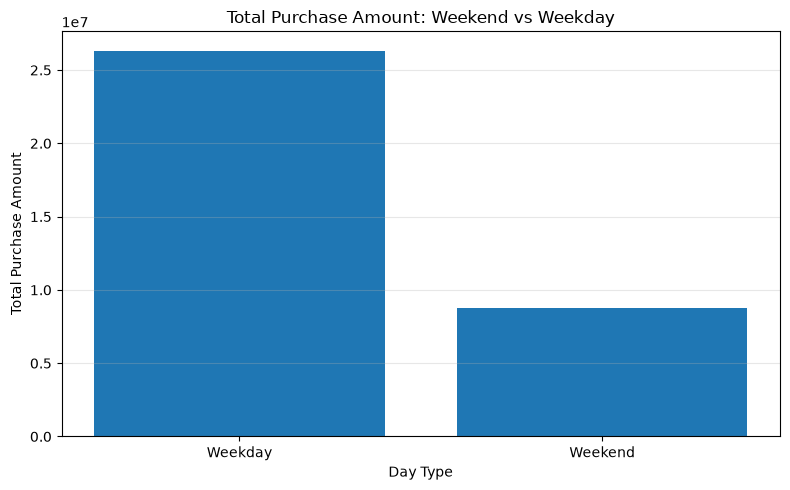

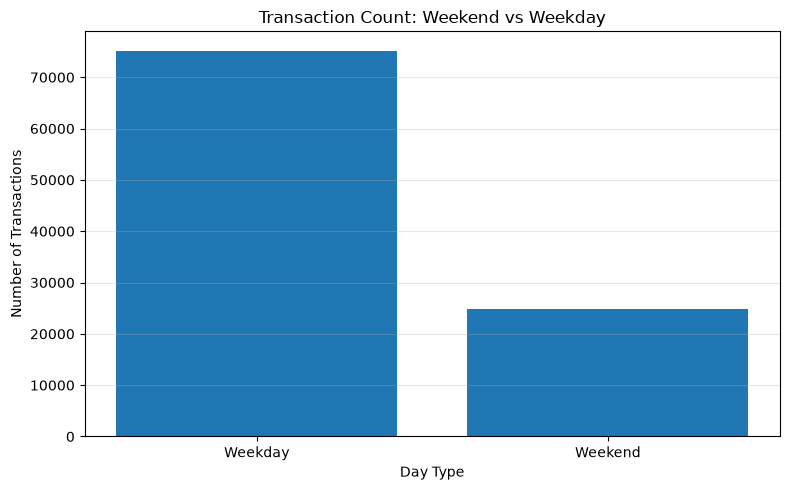


Observation 1:
More transactions occurred on weekdays.

Observation 2:
Average transaction value was higher on weekends.

Caution:
This is a descriptive comparison. Differences may reflect promotions, seasonality, or unequal numbers of weekend and weekday days. The comparison does not establish causation.


In [19]:
# TODO: Create readable labels from is_weekend and aggregate the metrics.


import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Create readable labels
df["day_type"] = df["is_weekend"].map({
    0: "Weekday",
    1: "Weekend",
    False: "Weekday",
    True: "Weekend"
})

# Step 2: Group by day type and calculate metrics
day_summary = df.groupby("day_type").agg(
    transaction_count=("transaction_id", "nunique"),
    total_purchase_amount=("purchase_amount", "sum"),
    avg_transaction_value=("purchase_amount", "mean"),
    avg_quantity=("quantity", "mean"),
    avg_discount_percentage=("discount_pct", "mean")
).reset_index()

# Step 3: Display the summary
print("Weekend vs Weekday Summary:")
display(day_summary.round(2))

# Step 4: Plot total purchase amount
plt.figure(figsize=(8, 5))
plt.bar(
    day_summary["day_type"],
    day_summary["total_purchase_amount"]
)
plt.title("Total Purchase Amount: Weekend vs Weekday")
plt.xlabel("Day Type")
plt.ylabel("Total Purchase Amount")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 5: Plot transaction count
plt.figure(figsize=(8, 5))
plt.bar(
    day_summary["day_type"],
    day_summary["transaction_count"]
)
plt.title("Transaction Count: Weekend vs Weekday")
plt.xlabel("Day Type")
plt.ylabel("Number of Transactions")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 6: Compare weekend and weekday results
summary = day_summary.set_index("day_type")

if "Weekend" in summary.index and "Weekday" in summary.index:
    weekend = summary.loc["Weekend"]
    weekday = summary.loc["Weekday"]

    print("\nObservation 1:")
    if weekend["transaction_count"] > weekday["transaction_count"]:
        print("More transactions occurred on weekends.")
    elif weekend["transaction_count"] < weekday["transaction_count"]:
        print("More transactions occurred on weekdays.")
    else:
        print("Transaction counts were equal.")

    print("\nObservation 2:")
    if weekend["avg_transaction_value"] > weekday["avg_transaction_value"]:
        print("Average transaction value was higher on weekends.")
    elif weekend["avg_transaction_value"] < weekday["avg_transaction_value"]:
        print("Average transaction value was higher on weekdays.")
    else:
        print("Average transaction values were equal.")

    print("\nCaution:")
    print(
        "This is a descriptive comparison. Differences may reflect "
        "promotions, seasonality, or unequal numbers of weekend and "
        "weekday days. The comparison does not establish causation."
    )
else:
    print("One group is missing. Check df['is_weekend'].unique().")


In [17]:
print(df.columns.tolist())

['transaction_id', 'customer_id', 'age_group', 'gender', 'city', 'customer_segment', 'product_id', 'product_category', 'original_price', 'discount_pct', 'final_price', 'quantity', 'purchase_amount', 'payment_method', 'purchase_date', 'purchase_hour', 'is_weekend', 'is_black_friday', 'day_type']


## Unsolved Question 6 — City-level sales dashboard

Identify the top 10 cities by total purchase amount. Create:
1. a horizontal bar chart of total purchase amount by city;
2. a table showing transaction count, unique customers, total sales, and average transaction value.

What operational or marketing action might a retailer investigate based on the results? State what additional data would be needed before acting.

Top 10 Cities by Total Purchase Amount:


,city,transaction_count,unique_customers,total_sales,avg_transaction_value
0,Atlanta,10075,8734,3618348.52,359.14
5,Miami,10036,8763,3566829.80,355.40
2,Dallas,9990,8666,3547967.43,355.15
6,New York,10105,8790,3546500.70,350.96
7,Phoenix,10032,8696,3526014.43,351.48
1,Chicago,9954,8711,3512360.63,352.86
3,Houston,10024,8703,3474957.45,346.66
9,Seattle,10097,8765,3456842.39,342.36
8,San Francisco,9968,8660,3445376.30,345.64
4,Los Angeles,9719,8513,3430433.02,352.96


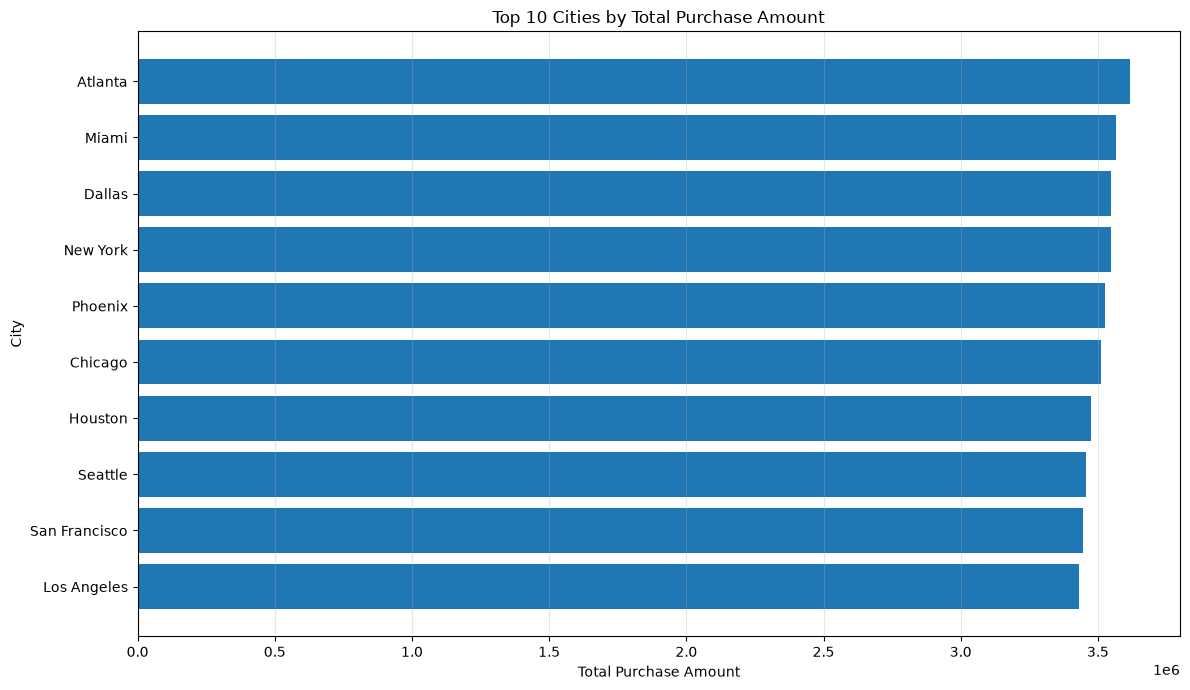


Leading City: Atlanta
Total Sales: 3618348.52
Transaction Count: 10075
Unique Customers: 8734
Average Transaction Value: 359.14

Recommendation:
Investigate whether the leading city needs additional inventory, staffing, or targeted marketing based on demand and sales patterns.

Additional Data Needed:
Before acting, examine profit margins, inventory availability, stockouts, staffing costs, marketing spend, sales trends over time, and customer acquisition and retention data.


In [20]:
# TODO: Group by city, aggregate the metrics, select the top 10, and plot.

import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Group by city and calculate the required metrics
city_summary = df.groupby("city").agg(
    transaction_count=("transaction_id", "nunique"),
    unique_customers=("customer_id", "nunique"),
    total_sales=("purchase_amount", "sum"),
    avg_transaction_value=("purchase_amount", "mean")
).reset_index()

# Step 2: Select the top 10 cities by total sales
top_10_cities = city_summary.sort_values(
    by="total_sales",
    ascending=False
).head(10)

# Step 3: Display the summary table
print("Top 10 Cities by Total Purchase Amount:")
display(top_10_cities.round(2))

# Step 4: Create a horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    top_10_cities["city"],
    top_10_cities["total_sales"]
)

plt.title("Top 10 Cities by Total Purchase Amount")
plt.xlabel("Total Purchase Amount")
plt.ylabel("City")
plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# Step 5: Identify the leading city
top_city = top_10_cities.iloc[0]

print("\nLeading City:", top_city["city"])
print("Total Sales:", round(top_city["total_sales"], 2))
print("Transaction Count:", top_city["transaction_count"])
print("Unique Customers:", top_city["unique_customers"])
print("Average Transaction Value:",
      round(top_city["avg_transaction_value"], 2))

# Step 6: Operational or marketing recommendation
print("\nRecommendation:")
print(
    "Investigate whether the leading city needs additional inventory, "
    "staffing, or targeted marketing based on demand and sales patterns."
)

print("\nAdditional Data Needed:")
print(
    "Before acting, examine profit margins, inventory availability, "
    "stockouts, staffing costs, marketing spend, sales trends over time, "
    "and customer acquisition and retention data."
)


## Submission checklist

- [ ] Loaded the provided CSV and confirmed its shape.
- [ ] Checked missing values, duplicates, and data types.
- [ ] Completed all 4 solved examples and reviewed their outputs.
- [ ] Attempted all 6 unsolved questions.
- [ ] Added a business interpretation to each unsolved task.
- [ ] Labeled charts clearly and used appropriate metrics.
- [ ] Avoided claims of causation from descriptive comparisons.
- [ ] Included a short conclusion with 3 data-backed findings and 2 limitations.

## Suggested extension (optional)

Use `statsmodels` to model purchase amount or quantity. Before fitting a model, define a specific question, select features that would be available at prediction time, inspect distributions and outliers, and split data appropriately if the goal is prediction. Do not interpret a model's associations as causal effects without a suitable causal design.